In [106]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from tensorflow import keras
from tensorflow.keras import models, layers

In [107]:
data_dir = "./data"        # use "data" if your notebook is at the top level of the repo
IMG_SIZE = (224, 224)       # your images are already 224 x 224

In [108]:
# One label number per folder, in alphabetical order
class_folders = sorted([f for f in os.listdir(data_dir)
                        if os.path.isdir(os.path.join(data_dir, f))])

class_names = class_folders          # folder names are the labels

print("Number of classes:", len(class_folders))
for i, folder in enumerate(class_folders):
    print(f"Label {i}: {folder}")

Number of classes: 20
Label 0: images_OBJ000
Label 1: images_OBJ001 
Label 2: images_OBJ002
Label 3: images_OBJ004
Label 4: images_OBJ006
Label 5: images_OBJ007
Label 6: images_OBJ011
Label 7: images_OBJ070
Label 8: images_OBJ108
Label 9: images_OBJ111
Label 10: images_OBJ123
Label 11: images_OBJ125
Label 12: images_OBJ201
Label 13: images_OBJ222
Label 14: images_OBJ523
Label 15: images_OBJ529
Label 16: images_OBJ608
Label 17: images_OBJ666
Label 18: images_OBJ777
Label 19: images_OBJ916


In [109]:
first_folder = os.path.join(data_dir, class_folders[0])
sample_file = [f for f in os.listdir(first_folder)
               if f.lower().endswith((".jpg", ".jpeg", ".png"))][0]

print("Sample image size:", Image.open(os.path.join(first_folder, sample_file)).size)

Sample image size: (224, 224)


In [110]:
X, y = [], []
valid_ext = (".jpg", ".jpeg", ".png")

for label, folder in enumerate(class_folders):
    folder_path = os.path.join(data_dir, folder)
    for file in os.listdir(folder_path):
        if file.lower().endswith(valid_ext):              # skips .DS_Store and other files
            img = Image.open(os.path.join(folder_path, file)).convert("RGB")
            img = img.resize(IMG_SIZE)
            X.append(np.array(img))
            y.append(label)

X = np.array(X, dtype="uint8")       # integers save memory: ~300 MB instead of ~1.2 GB
y = np.array(y)

print("Images:", X.shape)            # (2000, 224, 224, 3)
print("Labels:", y.shape)            # (2000,)
print("Images per label:", np.bincount(y))

Images: (2022, 224, 224, 3)
Labels: (2022,)
Images per label: [100 100 100 100 100 100 100 100 100 100 100 100 100 100 100 114 108 100
 100 100]


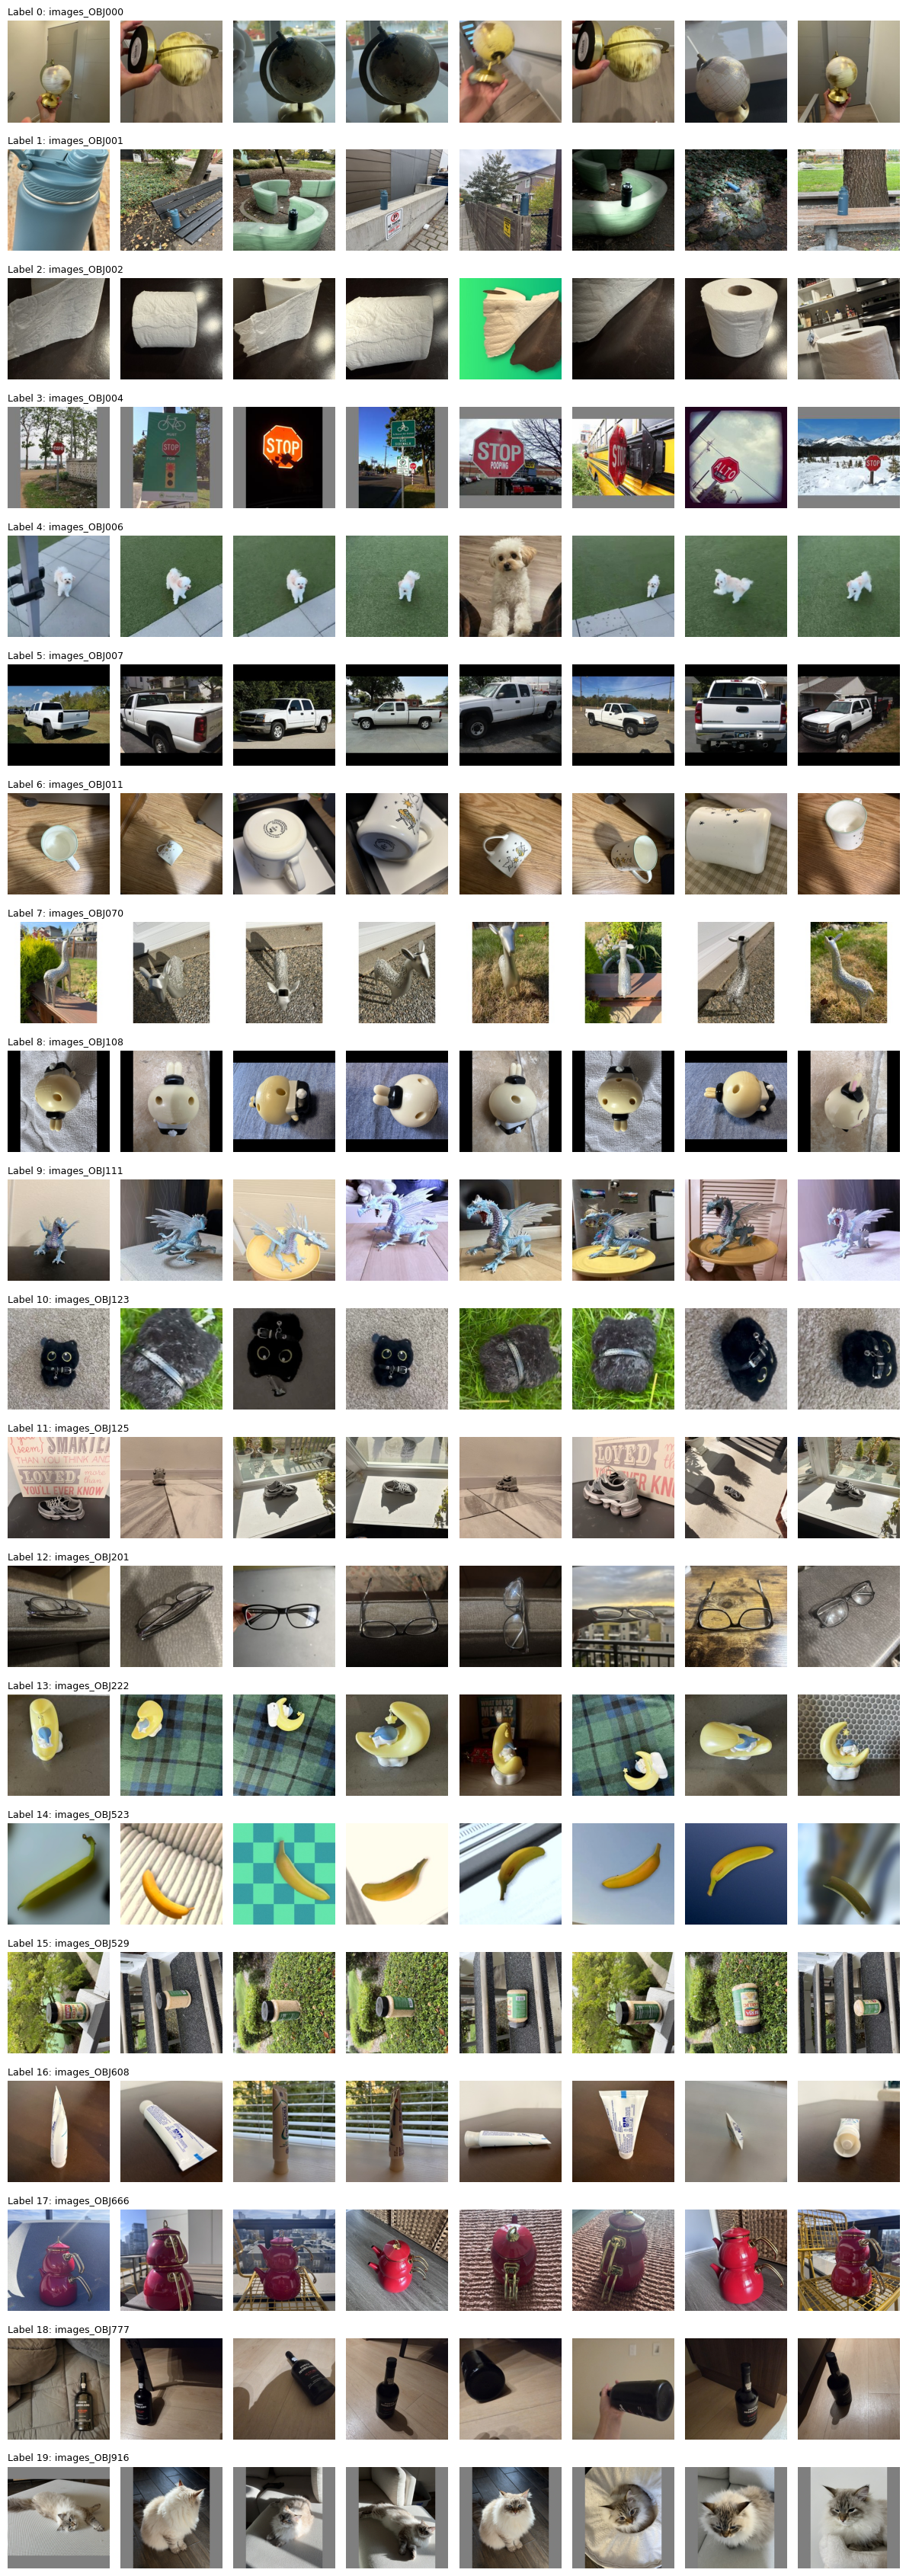

In [111]:
n_per_class = 8
n_classes = len(class_folders)

fig, axes = plt.subplots(n_classes, n_per_class,
                         figsize=(n_per_class * 1.5, n_classes * 1.7))

for label in range(n_classes):
    idx = np.where(y == label)[0][:n_per_class]           # first 8 images of this label
    for j in range(n_per_class):
        ax = axes[label, j]
        ax.axis("off")
        if j < len(idx):
            ax.imshow(X[idx[j]])
        if j == 0:
            ax.set_title(f"Label {label}: {class_names[label]}", loc="left", fontsize=9)

plt.tight_layout()
plt.show()

In [112]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

X_train = X_train.astype("float32") / 255.0      # scale pixels from 0–255 to 0–1
X_test  = X_test.astype("float32") / 255.0

print("Train:", X_train.shape, y_train.shape)    # (1600, 224, 224, 3)
print("Test: ", X_test.shape, y_test.shape)      # (400, 224, 224, 3)
print("Train images per label:", np.bincount(y_train))
print("Test images per label: ", np.bincount(y_test))

Train: (1617, 224, 224, 3) (1617,)
Test:  (405, 224, 224, 3) (405,)
Train images per label: [80 80 80 80 80 80 80 80 80 80 80 80 80 80 80 91 86 80 80 80]
Test images per label:  [20 20 20 20 20 20 20 20 20 20 20 20 20 20 20 23 22 20 20 20]


In [113]:
valid_ext = (".jpg", ".jpeg", ".png")

labels_table = pd.DataFrame({
    "Label": range(len(class_folders)),
    "Folder": class_folders,
    "Images": [len([f for f in os.listdir(os.path.join(data_dir, folder))
                    if f.lower().endswith(valid_ext)])
               for folder in class_folders]
})

print(labels_table.to_string(index=False))
print("\nTotal classes:", len(class_folders))
print("Total images:", labels_table["Images"].sum())

 Label         Folder  Images
     0  images_OBJ000     100
     1 images_OBJ001      100
     2  images_OBJ002     100
     3  images_OBJ004     100
     4  images_OBJ006     100
     5  images_OBJ007     100
     6  images_OBJ011     100
     7  images_OBJ070     100
     8  images_OBJ108     100
     9  images_OBJ111     100
    10  images_OBJ123     100
    11  images_OBJ125     100
    12  images_OBJ201     100
    13  images_OBJ222     100
    14  images_OBJ523     100
    15  images_OBJ529     114
    16  images_OBJ608     108
    17  images_OBJ666     100
    18  images_OBJ777     100
    19  images_OBJ916     100

Total classes: 20
Total images: 2022


In [122]:
from tensorflow import keras
from tensorflow.keras import models, layers
keras.utils.set_random_seed(42)
model_mlp = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Resizing(56, 56),
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dense(n_classes, activation='softmax')
])
model_mlp.summary()
model_mlp.summary()

model_mlp.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

history_mlp = model_mlp.fit(X_train, y_train,
                            epochs=50, batch_size=32,
                            validation_data=(X_test, y_test),
                            verbose=2)

test_loss_mlp, test_acc_mlp = model_mlp.evaluate(X_test, y_test, verbose=0)
print("MLP test accuracy:", round(test_acc_mlp, 4))

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_5 (Resizing)           │ (None, 56, 56, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 9408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 512)            │     4,817,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,984,212 (19.01 MB)

 Trainable params: 4,984,212 (19.01 MB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_5 (Resizing)           │ (None, 56, 56, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 9408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 512)            │     4,817,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,984,212 (19.01 MB)

 Trainable params: 4,984,212 (19.01 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
51/51 - 1s - 29ms/step - accuracy: 0.0878 - loss: 3.5342 - val_accuracy: 0.1951 - val_loss: 2.7436
Epoch 2/50
51/51 - 1s - 11ms/step - accuracy: 0.1849 - loss: 2.6851 - val_accuracy: 0.2543 - val_loss: 2.4295
Epoch 3/50
51/51 - 1s - 12ms/step - accuracy: 0.2183 - loss: 2.4539 - val_accuracy: 0.2568 - val_loss: 2.2812
Epoch 4/50
51/51 - 1s - 11ms/step - accuracy: 0.2542 - loss: 2.3907 - val_accuracy: 0.2667 - val_loss: 2.2480
Epoch 5/50
51/51 - 1s - 11ms/step - accuracy: 0.2486 - loss: 2.3352 - val_accuracy: 0.2864 - val_loss: 2.2353
Epoch 6/50
51/51 - 1s - 11ms/step - accuracy: 0.2486 - loss: 2.3224 - val_accuracy: 0.2864 - val_loss: 2.1651
Epoch 7/50
51/51 - 1s - 11ms/step - accuracy: 0.2740 - loss: 2.2382 - val_accuracy: 0.3210 - val_loss: 2.1228
Epoch 8/50
51/51 - 1s - 11ms/step - accuracy: 0.2771 - loss: 2.2255 - val_accuracy: 0.3160 - val_loss: 2.1208
Epoch 9/50
51/51 - 1s - 11ms/step - accuracy: 0.3086 - loss: 2.1428 - val_accuracy: 0.3235 - val_loss: 2.0790
Epoch 10/5

In [125]:
from tensorflow import keras
from tensorflow.keras import models, layers
keras.utils.set_random_seed(42)

model_cnn = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Data augmentation (only active during training)
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),

    # Block 1
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),            # 224 → 112

    # Block 2
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),            # 112 → 56

    # Block 3
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),            # 56 → 28

    # Block 4
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),            # 28 → 14

    # Classifier
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(128, activation='relu'),
    layers.Dense(n_classes, activation='softmax')
])
model_cnn.summary()

model_cnn.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

history_cnn = model_cnn.fit(X_train, y_train,
                            epochs=50, batch_size=32,
                            validation_data=(X_test, y_test),
                            verbose=2)

test_loss_cnn, test_acc_cnn = model_cnn.evaluate(X_test, y_test, verbose=0)
print("CNN test accuracy:", round(test_acc_cnn, 4))

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_2 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,892 (1.62 MB)

 Trainable params: 423,892 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
51/51 - 22s - 436ms/step - accuracy: 0.0618 - loss: 2.9838 - val_accuracy: 0.0988 - val_loss: 2.8638
Epoch 2/50
51/51 - 22s - 427ms/step - accuracy: 0.1379 - loss: 2.7714 - val_accuracy: 0.1407 - val_loss: 2.5945
Epoch 3/50
51/51 - 22s - 439ms/step - accuracy: 0.1688 - loss: 2.5684 - val_accuracy: 0.1679 - val_loss: 2.4571
Epoch 4/50
51/51 - 23s - 443ms/step - accuracy: 0.2016 - loss: 2.4581 - val_accuracy: 0.2247 - val_loss: 2.3378
Epoch 5/50
51/51 - 23s - 448ms/step - accuracy: 0.2263 - loss: 2.3749 - val_accuracy: 0.1951 - val_loss: 2.4589
Epoch 6/50
51/51 - 23s - 454ms/step - accuracy: 0.2610 - loss: 2.2629 - val_accuracy: 0.2420 - val_loss: 2.3540
Epoch 7/50
51/51 - 23s - 459ms/step - accuracy: 0.2870 - loss: 2.1658 - val_accuracy: 0.2815 - val_loss: 2.2957
Epoch 8/50
51/51 - 24s - 462ms/step - accuracy: 0.3197 - loss: 2.1023 - val_accuracy: 0.2938 - val_loss: 2.3475
Epoch 9/50
51/51 - 24s - 468ms/step - accuracy: 0.3309 - loss: 2.0504 - val_accuracy: 0.2716 - val_loss: